# Film Clustering and Cluster Interpretation

This notebook uses the processed feature outputs from the previous stage to build clustering representations, evaluate candidate clustering solutions, and interpret the resulting groups of films.

The objective is not only to partition the dataset, but also to identify clusters that are sufficiently coherent, reasonably balanced, and meaningful to interpret in domain terms.

In [1]:
import os

os.environ["OMP_NUM_THREADS"] = "1"
os.environ["MKL_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"
os.environ["NUMEXPR_NUM_THREADS"] = "1"

# new

In [2]:
from pathlib import Path
from collections import Counter
import ast

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.sparse import hstack, load_npz
from sklearn.cluster import KMeans, MiniBatchKMeans
from sklearn.decomposition import TruncatedSVD
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import normalize
from threadpoolctl import threadpool_limits

## 1. Load the saved feature artifacts

We begin by loading the processed dataframe together with the fitted transformation objects and the sparse feature matrices produced in the previous notebook. These artifacts define the representations that will be reused throughout the clustering stage.

In [3]:
PROJECT_ROOT = Path.cwd().parents[1]

OUTPUTS_DIR = PROJECT_ROOT / "outputs" / "text_clustering"
FEATURES_DIR = OUTPUTS_DIR / "features"
RESULTS_DIR = OUTPUTS_DIR / "results"

OUTPUTS_DIR.mkdir(parents=True, exist_ok=True)
FEATURES_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

PROCESSED_PATH = FEATURES_DIR / "processed_films.csv"

TFIDF_VECTORIZER_PATH = FEATURES_DIR / "tfidf_vectorizer.joblib"
GENRE_MLB_PATH = FEATURES_DIR / "genre_mlb.joblib"
KEYWORD_MLB_PATH = FEATURES_DIR / "keyword_mlb.joblib"
METADATA_OHE_PATH = FEATURES_DIR / "metadata_ohe.joblib"

X_PLOT_TFIDF_PATH = FEATURES_DIR / "X_plot_tfidf.npz"
X_GENRES_PATH = FEATURES_DIR / "X_genres.npz"
X_KEYWORDS_PATH = FEATURES_DIR / "X_keywords.npz"
X_METADATA_PATH = FEATURES_DIR / "X_metadata.npz"
X_PLOT_ONLY_PATH = FEATURES_DIR / "X_plot_only.npz"
X_FULL_BASELINE_PATH = FEATURES_DIR / "X_full_baseline.npz"

In [4]:
df = pd.read_csv(PROCESSED_PATH)

tfidf_vectorizer = joblib.load(TFIDF_VECTORIZER_PATH)
genre_mlb = joblib.load(GENRE_MLB_PATH)
keyword_mlb = joblib.load(KEYWORD_MLB_PATH)
metadata_ohe = joblib.load(METADATA_OHE_PATH)

X_plot_tfidf = load_npz(X_PLOT_TFIDF_PATH)
X_genres = load_npz(X_GENRES_PATH)
X_keywords = load_npz(X_KEYWORDS_PATH)
X_metadata = load_npz(X_METADATA_PATH)
X_plot_only = load_npz(X_PLOT_ONLY_PATH)
X_full_baseline = load_npz(X_FULL_BASELINE_PATH)

print("DataFrame shape:", df.shape)
print("X_plot_tfidf:", X_plot_tfidf.shape)
print("X_genres:", X_genres.shape)
print("X_keywords:", X_keywords.shape)
print("X_metadata:", X_metadata.shape)
print("X_plot_only:", X_plot_only.shape)
print("X_full_baseline:", X_full_baseline.shape)

DataFrame shape: (2000, 15)
X_plot_tfidf: (2000, 3946)
X_genres: (2000, 24)
X_keywords: (2000, 9327)
X_metadata: (2000, 74)
X_plot_only: (2000, 3946)
X_full_baseline: (2000, 13371)


In [5]:
if "title" in df.columns:
    display_col = "title"
else:
    display_col = df.columns[0]

print("Display column:", display_col)
df[[display_col]].head()

Display column: plotMedium


,plotMedium
0,"Poland, 1962. Anna, an orphan brought up by nu..."
1,Loosely-based on the true events of a homeless...
2,"Louis, a young teacher enamored of the age of ..."
3,"An outlandish science-fiction, comedy-thriller..."
4,"Mrs. Palfrey (Dame Joan Plowright), recently w..."


## 2. Construct the clustering representations

At this stage, we define the feature representations that can be used for clustering. In particular, we retain a plot-only representation and a hybrid representation, and we also construct a weighted hybrid variant in which narrative text contributes more strongly than the metadata blocks.

This allows us to evaluate whether stronger emphasis on plot information leads to more coherent thematic clusters.

In [6]:
PLOT_WEIGHT = 0.85
GENRE_WEIGHT = 0.55
KEYWORD_WEIGHT = 0.55
METADATA_WEIGHT = 0.20

X_plot_block = normalize(X_plot_tfidf, norm="l2", axis=1)
X_genres_block = normalize(X_genres, norm="l2", axis=1)
X_keywords_block = normalize(X_keywords, norm="l2", axis=1)
X_metadata_block = normalize(X_metadata, norm="l2", axis=1)

X_hybrid_weighted = hstack([
    X_plot_block * PLOT_WEIGHT,
    X_genres_block * GENRE_WEIGHT,
    X_keywords_block * KEYWORD_WEIGHT,
    X_metadata_block * METADATA_WEIGHT
]).tocsr()

print("Weighted hybrid matrix:", X_hybrid_weighted.shape)

Weighted hybrid matrix: (2000, 13371)


In [7]:
def prepare_matrix_for_clustering(matrix, n_components=150, random_state=42):
    X_norm = normalize(matrix, norm="l2", axis=1)

    max_components = min(X_norm.shape[0] - 1, X_norm.shape[1] - 1, n_components)
    if max_components < 2:
        raise ValueError("Not enough dimensions for TruncatedSVD.")

    svd = TruncatedSVD(n_components=max_components, random_state=random_state)
    X_reduced = svd.fit_transform(X_norm)
    X_reduced = normalize(X_reduced, norm="l2")
    

    explained_var = float(svd.explained_variance_ratio_.sum())
    return X_reduced, svd, explained_var

## 3. Evaluate candidate clustering solutions

We use KMeans as the baseline clustering method and examine several candidate values of \(k\) on the weighted hybrid representation.

The goal of this step is to narrow the search space using quantitative criteria. In particular, we inspect separation quality through the silhouette score, cluster size balance through the size distribution, and overall compactness through inertia before moving to a more detailed qualitative comparison of the most relevant candidate solutions.

In [8]:
def evaluate_kmeans_solutions(
    matrix,
    k_values,
    random_state=42,
    n_init=3,
    n_components=30,
    eval_sample_size=400,
    silhouette_sample_size=200
):
    rng = np.random.default_rng(random_state)

    n_rows = matrix.shape[0]
    sample_n = min(eval_sample_size, n_rows)

    sampled_idx = np.sort(rng.choice(n_rows, size=sample_n, replace=False))
    matrix_sample = matrix[sampled_idx]

    with threadpool_limits(limits=1):
        X_for_clustering, svd_model, explained_var = prepare_matrix_for_clustering(
            matrix_sample,
            n_components=n_components,
            random_state=random_state
        )

    results = []

    with threadpool_limits(limits=1):
        for k in k_values:
            model = MiniBatchKMeans(
                n_clusters=k,
                random_state=random_state,
                n_init=n_init,
                batch_size=256,
                max_iter=100,
                reassignment_ratio=0.01
            )

            labels = model.fit_predict(X_for_clustering)

            silhouette = silhouette_score(
                X_for_clustering,
                labels,
                sample_size=min(silhouette_sample_size, len(labels)),
                random_state=random_state
            )

            cluster_sizes = pd.Series(labels).value_counts().sort_index()

            results.append({
                "k": k,
                "silhouette_score": float(silhouette),
                "min_cluster_size": int(cluster_sizes.min()),
                "max_cluster_size": int(cluster_sizes.max()),
                "mean_cluster_size": float(cluster_sizes.mean()),
                "imbalance_ratio": float(cluster_sizes.max() / cluster_sizes.min()),
                "svd_explained_variance": float(explained_var),
                "evaluation_rows_used": int(sample_n),
                "inertia": float(model.inertia_)
            })

    return pd.DataFrame(results).sort_values("k").reset_index(drop=True)

In [9]:
K_VALUES = [4, 5, 6, 7, 8]

evaluation_weighted = evaluate_kmeans_solutions(
    X_hybrid_weighted,
    K_VALUES,
    n_init=3,
    n_components=30,
    eval_sample_size=400,
    silhouette_sample_size=200
)

display(
    evaluation_weighted[
        ["k", "silhouette_score", "imbalance_ratio", "min_cluster_size", "max_cluster_size", "inertia"]
    ]
)

,k,silhouette_score,imbalance_ratio,min_cluster_size,max_cluster_size,inertia
0,4,0.122788,1.810127,79,143,224.965342
1,5,0.130179,2.285714,56,128,210.376699
2,6,0.121717,3.212121,33,106,203.195161
3,7,0.100252,1.878049,41,77,198.360332
4,8,0.116006,2.555556,27,69,185.261625


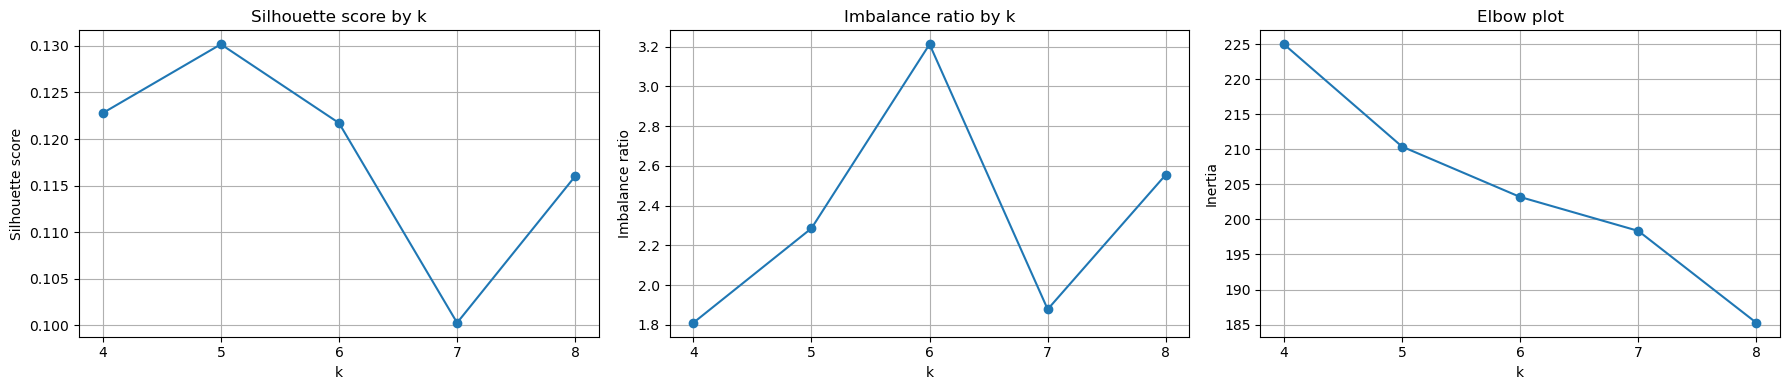

In [10]:
eval_plot = evaluation_weighted.sort_values("k")

fig, axes = plt.subplots(1, 3, figsize=(18, 4))

axes[0].plot(eval_plot["k"], eval_plot["silhouette_score"], marker="o")
axes[0].set_title("Silhouette score by k")
axes[0].set_xlabel("k")
axes[0].set_ylabel("Silhouette score")
axes[0].set_xticks(eval_plot["k"])
axes[0].grid(True)

axes[1].plot(eval_plot["k"], eval_plot["imbalance_ratio"], marker="o")
axes[1].set_title("Imbalance ratio by k")
axes[1].set_xlabel("k")
axes[1].set_ylabel("Imbalance ratio")
axes[1].set_xticks(eval_plot["k"])
axes[1].grid(True)

axes[2].plot(eval_plot["k"], eval_plot["inertia"], marker="o")
axes[2].set_title("Elbow plot")
axes[2].set_xlabel("k")
axes[2].set_ylabel("Inertia")
axes[2].set_xticks(eval_plot["k"])
axes[2].grid(True)

plt.tight_layout()
plt.show()

## 4. Compare the final candidate solutions

After the quantitative screening step, we retain \(k=5\) and \(k=6\) as the most relevant candidate solutions for closer inspection on the full weighted hybrid representation.

The purpose of this section is to move from aggregate metrics to structural comparison. We first examine the full cluster size distributions and then prepare the ground for the more detailed cluster profiling step that follows.

In [11]:
def run_full_clustering(matrix, base_df, k, n_components=150, random_state=42, n_init=10):
    X_for_clustering, svd_model, explained_var = prepare_matrix_for_clustering(
        matrix,
        n_components=n_components,
        random_state=random_state
    )

    model = KMeans(
        n_clusters=k,
        random_state=random_state,
        n_init=n_init,
        max_iter=300,
        algorithm="elkan"
    )

    with threadpool_limits(limits=1):
        labels = model.fit_predict(X_for_clustering)

    df_result = base_df.copy()
    df_result["cluster"] = labels

    cluster_sizes = (
        df_result["cluster"]
        .value_counts()
        .sort_index()
        .rename_axis("cluster")
        .reset_index(name="size")
    )

    return {
        "k": k,
        "model": model,
        "df": df_result,
        "labels": labels,
        "X_for_clustering": X_for_clustering,
        "svd_explained_variance": explained_var,
        "cluster_sizes": cluster_sizes
    }

In [12]:
run_k5 = run_full_clustering(X_hybrid_weighted, df, k=5)
run_k6 = run_full_clustering(X_hybrid_weighted, df, k=6)

print("k=5 cluster sizes")
display(run_k5["cluster_sizes"])

print("k=6 cluster sizes")
display(run_k6["cluster_sizes"])

k=5 cluster sizes


,cluster,size
0,0,381
1,1,411
2,2,301
3,3,357
4,4,550


k=6 cluster sizes


,cluster,size
0,0,361
1,1,392
2,2,290
3,3,374
4,4,294
5,5,289


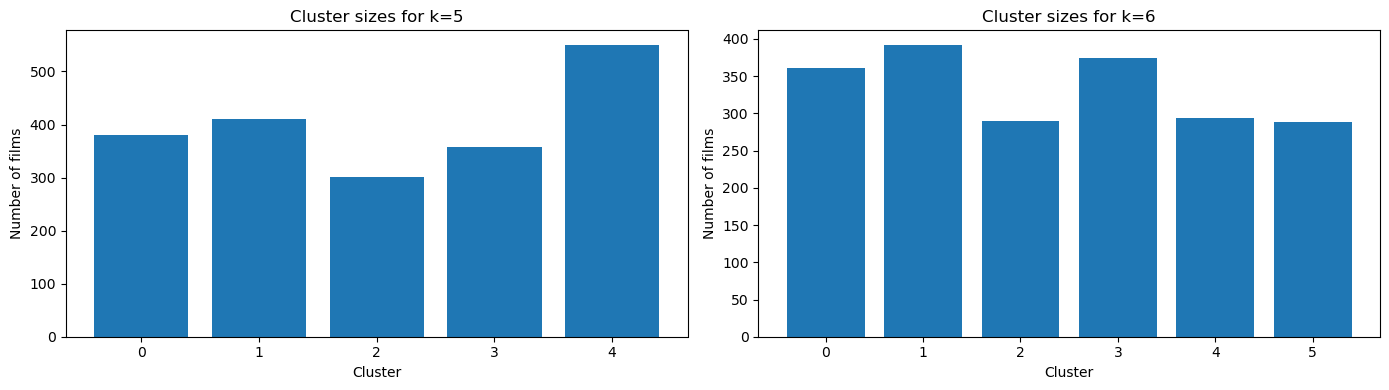

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].bar(run_k5["cluster_sizes"]["cluster"].astype(str), run_k5["cluster_sizes"]["size"])
axes[0].set_title("Cluster sizes for k=5")
axes[0].set_xlabel("Cluster")
axes[0].set_ylabel("Number of films")

axes[1].bar(run_k6["cluster_sizes"]["cluster"].astype(str), run_k6["cluster_sizes"]["size"])
axes[1].set_title("Cluster sizes for k=6")
axes[1].set_xlabel("Cluster")
axes[1].set_ylabel("Number of films")

plt.tight_layout()
plt.show()

## 5. Build cluster profiles

Quantitative metrics alone are not sufficient for selecting a final clustering solution. For this reason, we build descriptive cluster profiles that allow us to interpret what each group represents in substantive terms.

For each cluster, we summarize its dominant vocabulary, genre composition, recurring keywords, prevailing production context, and a small set of representative films. This makes it possible to assess whether the discovered clusters correspond to recognizable thematic or stylistic groupings rather than arbitrary partitions of the feature space.

In [14]:
tfidf_feature_names = tfidf_vectorizer.get_feature_names_out()

In [15]:
import numpy as np
import pandas as pd

def get_representative_films(matrix, model, labels, cluster_id, df, title_col, top_n=5):
    cluster_indices = np.where(labels == cluster_id)[0]

    if len(cluster_indices) == 0:
        return pd.DataFrame(columns=[title_col])

    X_cluster = np.asarray(matrix[cluster_indices])
    centroid = np.asarray(model.cluster_centers_[cluster_id]).ravel()

    distances = ((X_cluster - centroid) ** 2).sum(axis=1)
    closest_local_idx = np.argsort(distances)[:top_n]
    closest_global_idx = cluster_indices[closest_local_idx]

    return df.iloc[closest_global_idx][[title_col]].reset_index(drop=True)

In [16]:
from collections import Counter
import ast
import numpy as np
import pandas as pd


def safe_parse_list(value):
    if isinstance(value, list):
        return value
    if pd.isna(value):
        return []
    if isinstance(value, str):
        value = value.strip()
        if not value:
            return []
        try:
            parsed = ast.literal_eval(value)
            if isinstance(parsed, list):
                return parsed
        except Exception:
            pass
        return [item.strip() for item in value.split(",") if item.strip()]
    return []


def get_existing_column(df, candidates, default=None):
    for col in candidates:
        if col in df.columns:
            return col
    return default


def top_terms_from_cluster_mean(X_tfidf, labels, cluster_id, feature_names, top_n=8):
    cluster_rows = X_tfidf[labels == cluster_id]
    mean_vector = np.asarray(cluster_rows.mean(axis=0)).ravel()
    top_idx = np.argsort(mean_vector)[::-1][:top_n]
    return [feature_names[i] for i in top_idx]


def build_cluster_profiles(
    df_clustered,
    model,
    matrix_for_clustering,
    top_terms_n=8,
    top_genres_n=5,
    top_keywords_n=5,
    top_representatives_n=5
):
    labels = df_clustered["cluster"].to_numpy()
    profiles = []

    genres_col = get_existing_column(
        df_clustered,
        ["genres_list_parsed", "genres_list", "genres", "genres_clean"]
    )

    keywords_col = get_existing_column(
        df_clustered,
        ["keywords_filtered_parsed", "keywords_filtered", "keywords", "keywords_clean"]
    )

    country_col = get_existing_column(
        df_clustered,
        ["mainCountry_clean", "mainCountry", "country"]
    )

    language_col = get_existing_column(
        df_clustered,
        ["firstLanguage_clean", "firstLanguage", "language"]
    )

    for cluster_id in sorted(df_clustered["cluster"].unique()):
        cluster_df = df_clustered[df_clustered["cluster"] == cluster_id].copy()

        top_terms = top_terms_from_cluster_mean(
            X_plot_tfidf,
            labels,
            cluster_id,
            tfidf_feature_names,
            top_n=top_terms_n
        )

        genre_counter = Counter()
        if genres_col is not None:
            for items in cluster_df[genres_col]:
                genre_counter.update(safe_parse_list(items))

        keyword_counter = Counter()
        if keywords_col is not None:
            for items in cluster_df[keywords_col]:
                keyword_counter.update(safe_parse_list(items))

        dominant_country = "unknown"
        if country_col is not None:
            mode_vals = cluster_df[country_col].dropna().mode()
            if not mode_vals.empty:
                dominant_country = mode_vals.iloc[0]

        dominant_language = "unknown"
        if language_col is not None:
            mode_vals = cluster_df[language_col].dropna().mode()
            if not mode_vals.empty:
                dominant_language = mode_vals.iloc[0]

        representative_films = get_representative_films(
            matrix=matrix_for_clustering,
            model=model,
            labels=labels,
            cluster_id=cluster_id,
            df=df_clustered,
            title_col=display_col,
            top_n=top_representatives_n
        )[display_col].tolist()

        profiles.append({
            "cluster": int(cluster_id),
            "size": int(len(cluster_df)),
            "top_terms": ", ".join(top_terms),
            "top_genres": ", ".join([g for g, _ in genre_counter.most_common(top_genres_n)]),
            "top_keywords": ", ".join([k for k, _ in keyword_counter.most_common(top_keywords_n)]),
            "dominant_country": dominant_country,
            "dominant_language": dominant_language,
            "representative_films": " | ".join(representative_films),
        })

    return pd.DataFrame(profiles).sort_values("cluster").reset_index(drop=True)

In [17]:
cluster_profiles_k5_df = build_cluster_profiles(
    df_clustered=run_k5["df"],
    model=run_k5["model"],
    matrix_for_clustering=run_k5["X_for_clustering"]
)

cluster_profiles_k6_df = build_cluster_profiles(
    df_clustered=run_k6["df"],
    model=run_k6["model"],
    matrix_for_clustering=run_k6["X_for_clustering"]
)

print("Cluster profiles for k=5")
display(cluster_profiles_k5_df)

print("Cluster profiles for k=6")
display(cluster_profiles_k6_df)

Cluster profiles for k=5


,cluster,size,top_terms,top_genres,top_keywords,dominant_country,dominant_language,representative_films
0,0,381,"house, night, dr, soon, blood, mysterious, gro...","horror, thriller, mystery, drama, sci-fi","murder, blood, psychotronic film, death, violence",gb,en,A young psychiatrist interviews four inmates i...
1,1,411,"police, death, wife, finds, soon, daughter, lo...","thriller, drama, crime, mystery, action","murder, death, violence, blood, flashback",gb,en,"Wealthy, brilliant, and meticulous Ted Crawfor..."
2,2,301,"bond, help, mission, named, friends, journey, ...","adventure, fantasy, family, comedy, action","murder, explosion, rescue, character name in t...",gb,en,The tale of three unlikely heroes - a misfit m...
3,3,357,"friends, just, father, mother, friend, best, w...","comedy, drama, romance, crime, action","husband wife relationship, female nudity, kiss...",gb,en,Emily Jackson lives a fast-paced life. Always ...
4,4,550,"war, old, mother, year, father, years, film, l...","drama, romance, biography, history, war","female nudity, husband wife relationship, deat...",gb,en,"Overwhelmed at work and lonely at home, a coun..."


Cluster profiles for k=6


,cluster,size,top_terms,top_genres,top_keywords,dominant_country,dominant_language,representative_films
0,0,361,"house, night, soon, blood, dr, mysterious, gro...","horror, thriller, mystery, drama, sci-fi","murder, blood, psychotronic film, death, violence",gb,en,A young psychiatrist interviews four inmates i...
1,1,392,"war, mother, year, film, old, father, people, ...","drama, history, biography, war, crime","based on true story, murder, husband wife rela...",gb,en,Upon his father's death. Jake revisits the wor...
2,2,290,"friends, just, friend, best, town, father, sch...","comedy, drama, romance, crime, action","female nudity, husband wife relationship, inde...",gb,en,Professors Vooshka and Crump decide to visit a...
3,3,374,"police, soon, wife, daughter, death, finds, de...","thriller, drama, crime, mystery, action","murder, death, violence, blood, female nudity",gb,en,"Harold (Bob Hoskins), a prosperous English gan..."
4,4,294,"old, meets, wife, mother, relationship, husban...","romance, drama, comedy, biography, thriller","kiss, husband wife relationship, female nudity...",gb,en,Sonia is a member of a closed Hasidic communit...
5,5,289,"bond, help, mission, friends, father, named, j...","adventure, fantasy, family, comedy, action","explosion, murder, rescue, character name in t...",gb,en,Jason has been prophesied to take the throne o...


## 6. Select the final clustering solution

After combining the quantitative evidence with the cluster-level interpretation, we retain both \(k=5\) and \(k=6\) for reporting purposes, but we select \(k=6\) as the final solution.

The main reason for this choice is that \(k=6\) yields a more distinct thematic separation between clusters while still maintaining an acceptable overall structure. Below, we display the size distribution and the descriptive profiles of the selected solution.

In [18]:
SELECTED_K = 6
selected_run = run_k6
selected_cluster_profiles = cluster_profiles_k6_df

print(f"Selected final solution: k = {SELECTED_K}")
print("Selected cluster sizes:")
display(selected_run["cluster_sizes"])

print("Selected cluster profiles:")
display(selected_cluster_profiles)

Selected final solution: k = 6
Selected cluster sizes:


,cluster,size
0,0,361
1,1,392
2,2,290
3,3,374
4,4,294
5,5,289


Selected cluster profiles:


,cluster,size,top_terms,top_genres,top_keywords,dominant_country,dominant_language,representative_films
0,0,361,"house, night, soon, blood, dr, mysterious, gro...","horror, thriller, mystery, drama, sci-fi","murder, blood, psychotronic film, death, violence",gb,en,A young psychiatrist interviews four inmates i...
1,1,392,"war, mother, year, film, old, father, people, ...","drama, history, biography, war, crime","based on true story, murder, husband wife rela...",gb,en,Upon his father's death. Jake revisits the wor...
2,2,290,"friends, just, friend, best, town, father, sch...","comedy, drama, romance, crime, action","female nudity, husband wife relationship, inde...",gb,en,Professors Vooshka and Crump decide to visit a...
3,3,374,"police, soon, wife, daughter, death, finds, de...","thriller, drama, crime, mystery, action","murder, death, violence, blood, female nudity",gb,en,"Harold (Bob Hoskins), a prosperous English gan..."
4,4,294,"old, meets, wife, mother, relationship, husban...","romance, drama, comedy, biography, thriller","kiss, husband wife relationship, female nudity...",gb,en,Sonia is a member of a closed Hasidic communit...
5,5,289,"bond, help, mission, friends, father, named, j...","adventure, fantasy, family, comedy, action","explosion, murder, rescue, character name in t...",gb,en,Jason has been prophesied to take the throne o...


## 7. Save clustering outputs

Finally, we export the clustering assignments, cluster size tables, cluster profile tables, and evaluation results so that the selected and alternative solutions can be reused in the report and in any follow-up analysis.

In [19]:
clustered_films_k5_path = RESULTS_DIR / "clustered_films_k5.csv"
clustered_films_k6_path = RESULTS_DIR / "clustered_films_k6.csv"

cluster_profiles_k5_path = RESULTS_DIR / "cluster_profiles_k5.csv"
cluster_profiles_k6_path = RESULTS_DIR / "cluster_profiles_k6.csv"

cluster_sizes_k5_path = RESULTS_DIR / "cluster_sizes_k5.csv"
cluster_sizes_k6_path = RESULTS_DIR / "cluster_sizes_k6.csv"

evaluation_weighted_path = RESULTS_DIR / "evaluation_weighted.csv"

run_k5["df"].to_csv(clustered_films_k5_path, index=False)
run_k6["df"].to_csv(clustered_films_k6_path, index=False)

cluster_profiles_k5_df.to_csv(cluster_profiles_k5_path, index=False)
cluster_profiles_k6_df.to_csv(cluster_profiles_k6_path, index=False)

run_k5["cluster_sizes"].to_csv(cluster_sizes_k5_path, index=False)
run_k6["cluster_sizes"].to_csv(cluster_sizes_k6_path, index=False)

evaluation_weighted.to_csv(evaluation_weighted_path, index=False)

print("Saved clustered films k=5 to:", clustered_films_k5_path)
print("Saved clustered films k=6 to:", clustered_films_k6_path)
print("Saved cluster profiles k=5 to:", cluster_profiles_k5_path)
print("Saved cluster profiles k=6 to:", cluster_profiles_k6_path)
print("Saved cluster sizes k=5 to:", cluster_sizes_k5_path)
print("Saved cluster sizes k=6 to:", cluster_sizes_k6_path)
print("Saved evaluation table to:", evaluation_weighted_path)

Saved clustered films k=5 to: c:\Users\Georg\Desktop\DTU\FATA\FataProject\outputs\text_clustering\results\clustered_films_k5.csv
Saved clustered films k=6 to: c:\Users\Georg\Desktop\DTU\FATA\FataProject\outputs\text_clustering\results\clustered_films_k6.csv
Saved cluster profiles k=5 to: c:\Users\Georg\Desktop\DTU\FATA\FataProject\outputs\text_clustering\results\cluster_profiles_k5.csv
Saved cluster profiles k=6 to: c:\Users\Georg\Desktop\DTU\FATA\FataProject\outputs\text_clustering\results\cluster_profiles_k6.csv
Saved cluster sizes k=5 to: c:\Users\Georg\Desktop\DTU\FATA\FataProject\outputs\text_clustering\results\cluster_sizes_k5.csv
Saved cluster sizes k=6 to: c:\Users\Georg\Desktop\DTU\FATA\FataProject\outputs\text_clustering\results\cluster_sizes_k6.csv
Saved evaluation table to: c:\Users\Georg\Desktop\DTU\FATA\FataProject\outputs\text_clustering\results\evaluation_weighted.csv


## Output of this notebook

By the end of this notebook, we have produced the clustering results for the main candidate values of \(k\), the final selected clustering solution, and interpretable cluster profiles that can support the discussion in the report.

Possible next steps include relating the clusters to external outcome variables, comparing them in terms of ratings or popularity, and using the fitted representations to position new film descriptions within the same feature space.